# Baseline models

Baselines for 3-class sentiment (negative / neutral / positive) on Financial PhraseBank.
All models are trained on `train.csv` and evaluated on `val.csv`.

Main metric: **macro F1**, because the classes are imbalanced (59% neutral, 12% negative). A model that never predicts negative can still get a good accuracy, but not a good macro F1.

Models in this notebook:
1. TF-IDF + logistic regression
2. LSTM with random embeddings
3. CNN with random embeddings (frozen and fine-tuned)

The CNN with FinBERT embeddings is in notebook 02 and the FinBERT transformer in notebook 05.

### Load required packages

In [16]:
import os
import re

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import keras
from keras.models import Sequential
from keras.layers import Input, Embedding, LSTM, Dense, Dropout, SpatialDropout1D, Conv1D, GlobalMaxPooling1D
from keras.optimizers import Adam
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping, Callback
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# FinBERT is downloaded into the project folder
os.environ["HF_HOME"] = os.path.abspath("../.cache/huggingface")
os.environ["HF_HUB_CACHE"] = os.path.abspath("../.cache/huggingface/hub")
from transformers import BertModel, BertTokenizerFast

# Fix the random seed
keras.utils.set_random_seed(42)

/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1108 16:48:58.365000 42097 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


### Loading the dataset

In [17]:
train = pd.read_csv("../data/train.csv")
val = pd.read_csv("../data/val.csv")
print(train.shape, val.shape)
train.head()

(2901, 2) (967, 2)


,label,sentence
0,negative,The fair value of the company 's investment pr...
1,neutral,"Trading under the name Velta UK , a former Upo..."
2,positive,"Via the move , the company aims annual savings..."
3,positive,The company also estimates the already carried...
4,positive,"However , the proportion of the paid standing ..."


In [18]:
train.label.value_counts(normalize=True)

label
neutral     0.593588
positive    0.281627
negative    0.124785
Name: proportion, dtype: float64

In [19]:
# encode the labels as negative = 0, neutral = 1, positive = 2
LABELS = ["negative", "neutral", "positive"]
y_train = train.label.map({"negative": 0, "neutral": 1, "positive": 2}).values
y_val = val.label.map({"negative": 0, "neutral": 1, "positive": 2}).values

In [20]:
lengths = [len(s.split()) for s in train.sentence]
print("Longest sentence:", max(lengths), "words")
print("Median length:", int(np.median(lengths)), "words")

Longest sentence: 81 words
Median length: 22 words


### Preprocessing

We lowercase every sentence and replace every number with `<num>`. The sentiment depends on the structure ("profit rose to <num>") and not on the exact number (Symeonidis et al., 2018). This also makes the vocabulary smaller (7,840 to 7,081 words).

We do not remove stopwords: lists like NLTK's contain words such as *not*, *up* and *down*, which carry the sentiment in financial text.

In [21]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\d+([.,]\d+)*", " <num> ", text)   # 2.5 or 1,000 -> <num>
    text = re.sub(r"\s+", " ", text).strip()
    return text

print(train.sentence[0])
print(clean_text(train.sentence[0]))

The fair value of the company 's investment properties went down to EUR 2.768 billion at the end of 2009 from EUR 2.916 billion a year earlier .
the fair value of the company 's investment properties went down to eur <num> billion at the end of <num> from eur <num> billion a year earlier .


### Function to evaluate a model

Prints accuracy, macro F1 and the report per class, and saves the confusion matrix.

In [22]:
def evaluate(probs, name):
    pred = probs.argmax(axis=1)
    print("accuracy:", round(accuracy_score(y_val, pred), 4))
    print("macro F1:", round(f1_score(y_val, pred, average="macro"), 4))
    print(classification_report(y_val, pred, target_names=LABELS))
    disp = ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=LABELS, cmap="Reds")
    disp.ax_.set_title(name + ": confusion matrix (val)")
    plt.savefig("../results/figures/" + name.lower().replace(" ", "_").replace(",", "") + "_cm.png", dpi=150)
    plt.show()

## 1. TF-IDF + logistic regression

Unigrams and bigrams, so phrases like "went down" are one feature. The vectorizer is fitted on train only.

In [23]:
vectorizer = TfidfVectorizer(preprocessor=clean_text, tokenizer=str.split, token_pattern=None,
                             ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(train.sentence)
X_val_tfidf = vectorizer.transform(val.sentence)
print(X_train_tfidf.shape)

(2901, 39035)


In [24]:
logreg = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
logreg.fit(X_train_tfidf, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to 

accuracy: 0.7766
macro F1: 0.7172
              precision    recall  f1-score   support

    negative       0.75      0.55      0.63       121
     neutral       0.81      0.89      0.85       574
    positive       0.71      0.64      0.67       272

    accuracy                           0.78       967
   macro avg       0.76      0.69      0.72       967
weighted avg       0.77      0.78      0.77       967



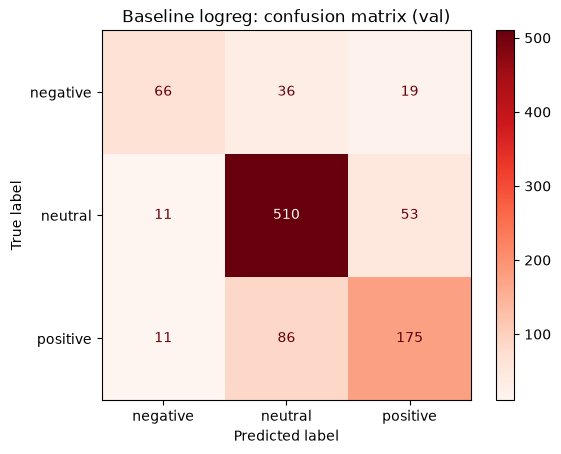

In [25]:
probs_logreg = logreg.predict_proba(X_val_tfidf)
evaluate(probs_logreg, "Baseline logreg")

## 2. LSTM

The Keras tokenizer turns every word into an integer (fitted on train only). Sentences are padded / cut to 64 tokens.

In [26]:
filters = '!"#$&()*+,-./:;=?@[\\]^_`{|}~\t\n'   # Keras default without < and >, so <num> stays one token
tokenizer = Tokenizer(oov_token="<OOV>", filters=filters)
tokenizer.fit_on_texts(train.sentence.apply(clean_text))

X_train = pad_sequences(tokenizer.texts_to_sequences(train.sentence.apply(clean_text)), maxlen=64, padding="post")
X_val = pad_sequences(tokenizer.texts_to_sequences(val.sentence.apply(clean_text)), maxlen=64, padding="post")
vocab_size = len(tokenizer.word_index) + 1
print(X_train.shape, X_val.shape, vocab_size)

(2901, 64) (967, 64) 7081


In [27]:
i = 0
print(train.sentence[i])
print(X_train[i])

The fair value of the company 's investment properties went down to EUR 2.768 billion at the end of 2009 from EUR 2.916 billion a year earlier .
[  3 571 111   4   3  13  11 100 572 461 112   7   9   2 163  27   3 138
   4   2  15   9   2 163   8  33 113   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0]


a. Define the model and print its summary

In [28]:
model_lstm = Sequential()
model_lstm.add(Input(shape=(64,)))
model_lstm.add(Embedding(vocab_size, 100, mask_zero=True))
model_lstm.add(LSTM(64))
model_lstm.add(Dropout(0.3))
model_lstm.add(Dense(3, activation="softmax"))
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 64, 100)        │       708,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 750,535 (2.86 MB)

 Trainable params: 750,535 (2.86 MB)

 Non-trainable params: 0 (0.00 B)

b. Compile the model

In [29]:
model_lstm.compile(optimizer=Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

c. Train the model (stops when the val loss has not improved for 3 epochs)

In [30]:
history_lstm = model_lstm.fit(X_train, to_categorical(y_train, 3),
                              validation_data=(X_val, to_categorical(y_val, 3)),
                              epochs=30, batch_size=32,
                              callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])

Epoch 1/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.6119 - loss: 0.8793 - val_accuracy: 0.6836 - val_loss: 0.7758
Epoch 2/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.7449 - loss: 0.5760 - val_accuracy: 0.6980 - val_loss: 0.7542
Epoch 3/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8600 - loss: 0.3610 - val_accuracy: 0.7322 - val_loss: 0.7804
Epoch 4/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9369 - loss: 0.1910 - val_accuracy: 0.7032 - val_loss: 0.8653
Epoch 5/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9669 - loss: 0.1243 - val_accuracy: 0.6939 - val_loss: 1.0851


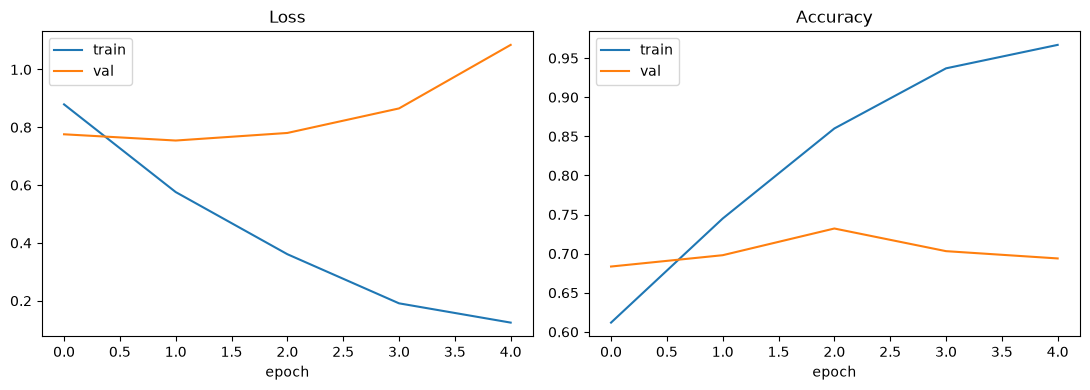

In [31]:
# visualise training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history_lstm.history["loss"], label="train")
ax1.plot(history_lstm.history["val_loss"], label="val")
ax1.set_title("Loss")
ax1.set_xlabel("epoch")
ax1.legend()
ax2.plot(history_lstm.history["accuracy"], label="train")
ax2.plot(history_lstm.history["val_accuracy"], label="val")
ax2.set_title("Accuracy")
ax2.set_xlabel("epoch")
ax2.legend()
plt.tight_layout()
plt.savefig("../results/figures/baseline_lstm_loss.png", dpi=150)
plt.show()

accuracy: 0.698
macro F1: 0.4646
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       121
     neutral       0.78      0.89      0.83       574
    positive       0.52      0.61      0.56       272

    accuracy                           0.70       967
   macro avg       0.44      0.50      0.46       967
weighted avg       0.61      0.70      0.65       967



/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zer

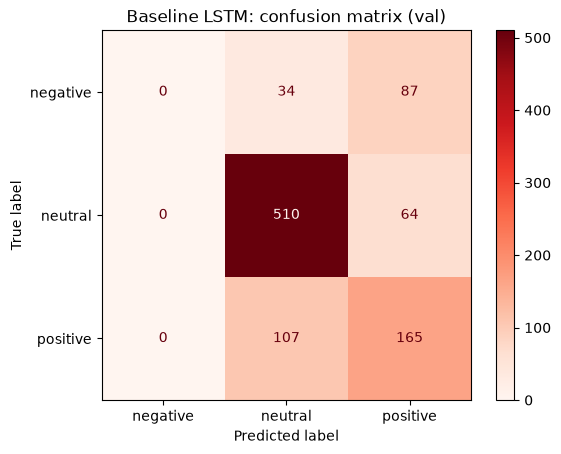

In [32]:
probs_lstm = model_lstm.predict(X_val, verbose=0)
evaluate(probs_lstm, "Baseline LSTM")

Logistic regression is better than the LSTM. The most likely reason is the data size: the LSTM has ~750k parameters and only 2,901 training sentences, so it overfits after ~2 epochs. The sentences are also short (median 21 words), so modelling word order does not help much.

## 3. CNN with random embeddings

Same CNN as the FinBERT CNN in notebook 02, but the embedding matrix is **random numbers** with the same shape and scale as FinBERT's.
The only thing missing is the pretrained knowledge, so the gap to the FinBERT CNN shows how much the pretrained embeddings add.

- **random frozen:** the random vectors never change (the floor)
- **random fine-tuned:** the embeddings are learned from the 2,901 training sentences only

The CNN uses FinBERT's word pieces as tokens (not the LSTM tokenizer above), so it is the same input as in notebook 02.

In [33]:
bert_tokenizer = BertTokenizerFast.from_pretrained("yiyanghkust/finbert-pretrain")
X_train_wp = bert_tokenizer(list(train.sentence), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]
X_val_wp = bert_tokenizer(list(val.sentence), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]

# we only need FinBERT's embedding matrix for its shape and scale
finbert = BertModel.from_pretrained("yiyanghkust/finbert-pretrain")
finbert_matrix = finbert.embeddings.word_embeddings.weight.detach().numpy()
del finbert

rng = np.random.default_rng(42)
random_matrix = rng.normal(0, finbert_matrix.std(), finbert_matrix.shape).astype("float32")
print(X_train_wp.shape, random_matrix.shape)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 30540.30it/s]
[transformers] BertModel LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(2901, 64) (30873, 768)


After every epoch we compute macro F1 on val, so early stopping can use it (Keras only has accuracy and loss built in).

In [34]:
class MacroF1(Callback):
    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(X_val_wp, batch_size=32, verbose=0).argmax(axis=1)
        logs["val_macro_f1"] = f1_score(y_val, pred, average="macro")

In [35]:
def build_cnn(embedding_matrix, trainable):
    model = Sequential()
    model.add(Input(shape=(64,)))
    # start from zeros and copy the matrix in below (a Constant initializer uses too much memory)
    model.add(Embedding(embedding_matrix.shape[0], embedding_matrix.shape[1], embeddings_initializer="zeros", trainable=trainable))
    model.add(SpatialDropout1D(0.3))
    model.add(Conv1D(64, 3, activation="relu"))
    model.add(GlobalMaxPooling1D())
    model.add(Dense(32, activation="relu"))
    model.add(Dropout(0.5))
    model.add(Dense(3, activation="softmax"))
    model.layers[0].set_weights([embedding_matrix])
    model.compile(optimizer=Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
    return model

### a. Random frozen

In [36]:
keras.utils.set_random_seed(42)
cnn_frozen = build_cnn(random_matrix, trainable=False)
cnn_frozen.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 64, 768)        │    23,710,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 64, 768)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 62, 64)         │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,860,163 (91.02 MB)

 Trainable params: 149,699 (584.76 KB)

 Non-trainable params: 23,710,464 (90.45 MB)

In [37]:
early_stop = EarlyStopping(monitor="val_macro_f1", mode="max", patience=5, restore_best_weights=True)
history_frozen = cnn_frozen.fit(X_train_wp, to_categorical(y_train, 3),
                                validation_data=(X_val_wp, to_categorical(y_val, 3)),
                                epochs=20, batch_size=32, verbose=0, callbacks=[MacroF1(), early_stop])

accuracy: 0.7415
macro F1: 0.6597
              precision    recall  f1-score   support

    negative       0.77      0.42      0.55       121
     neutral       0.76      0.89      0.82       574
    positive       0.67      0.56      0.61       272

    accuracy                           0.74       967
   macro avg       0.73      0.63      0.66       967
weighted avg       0.74      0.74      0.73       967



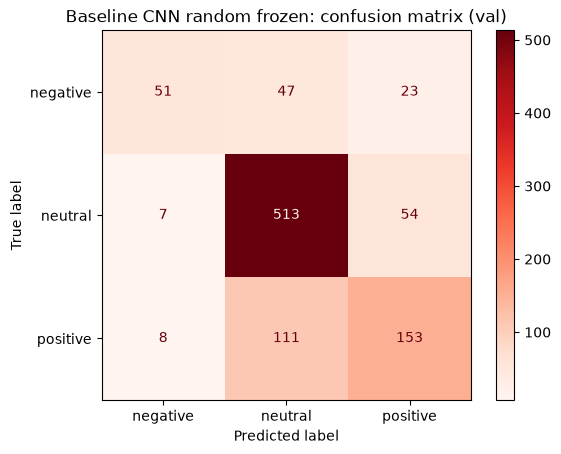

In [38]:
probs_random_frozen = cnn_frozen.predict(X_val_wp, batch_size=32, verbose=0)
evaluate(probs_random_frozen, "Baseline CNN random frozen")

### b. Random fine-tuned

In [39]:
keras.utils.set_random_seed(42)
cnn_finetuned = build_cnn(random_matrix, trainable=True)
cnn_finetuned.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 64, 768)        │    23,710,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 64, 768)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 62, 64)         │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,860,163 (91.02 MB)

 Trainable params: 23,860,163 (91.02 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
early_stop = EarlyStopping(monitor="val_macro_f1", mode="max", patience=5, restore_best_weights=True)
history_finetuned = cnn_finetuned.fit(X_train_wp, to_categorical(y_train, 3),
                                      validation_data=(X_val_wp, to_categorical(y_val, 3)),
                                      epochs=20, batch_size=32, verbose=0, callbacks=[MacroF1(), early_stop])

accuracy: 0.7839
macro F1: 0.706
              precision    recall  f1-score   support

    negative       0.83      0.45      0.58       121
     neutral       0.77      0.94      0.85       574
    positive       0.80      0.60      0.69       272

    accuracy                           0.78       967
   macro avg       0.80      0.66      0.71       967
weighted avg       0.79      0.78      0.77       967



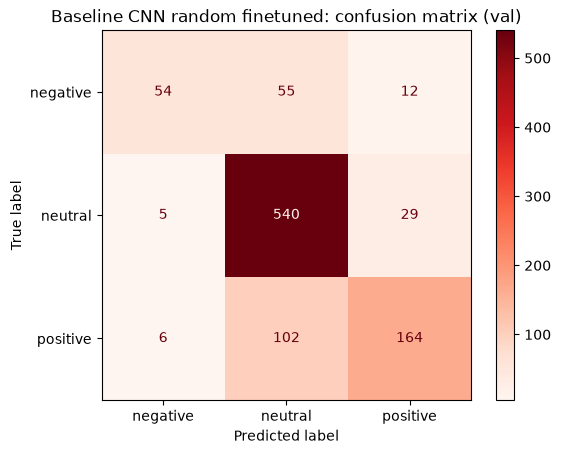

In [41]:
probs_random_finetuned = cnn_finetuned.predict(X_val_wp, batch_size=32, verbose=0)
evaluate(probs_random_finetuned, "Baseline CNN random finetuned")

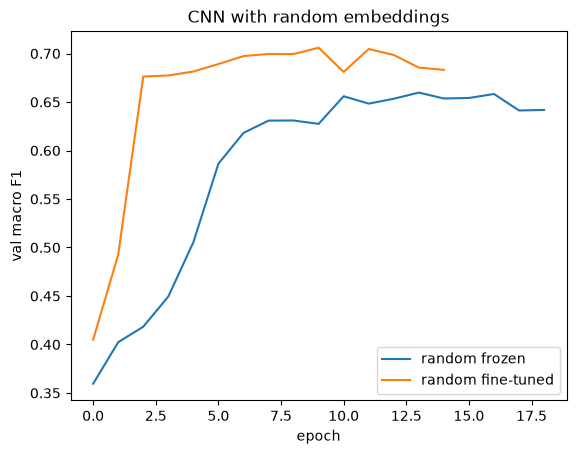

In [42]:
# visualise the val macro F1 of both CNNs
plt.plot(history_frozen.history["val_macro_f1"], label="random frozen")
plt.plot(history_finetuned.history["val_macro_f1"], label="random fine-tuned")
plt.title("CNN with random embeddings")
plt.xlabel("epoch")
plt.ylabel("val macro F1")
plt.legend()
plt.show()

## Save the results

One row per model in `results/metrics.csv` (a row of the same model is replaced, so running again does not add duplicates).
`hard` = the val sentences in the 0.4-0.6 confidence band of the FinBERT CNN (`results/hard_samples/band_val.csv`, notebook 02), the same for every model.

In [43]:
hard = pd.read_csv("../results/hard_samples/band_val.csv").is_hard.values

def metrics_row(probs, embedding_config, architecture):
    pred = probs.argmax(axis=1)
    per_class = f1_score(y_val, pred, labels=[0, 1, 2], average=None)
    return {"condition": "baseline", "embedding_config": embedding_config, "architecture": architecture,
            "accuracy_overall": accuracy_score(y_val, pred),
            "f1_overall": f1_score(y_val, pred, average="macro"),
            "accuracy_hard": accuracy_score(y_val[hard], pred[hard]),
            "f1_hard": f1_score(y_val[hard], pred[hard], average="macro"),
            "accuracy_nonhard": accuracy_score(y_val[~hard], pred[~hard]),
            "f1_nonhard": f1_score(y_val[~hard], pred[~hard], average="macro"),
            "f1_negative": per_class[0], "f1_neutral": per_class[1], "f1_positive": per_class[2]}

rows = [metrics_row(probs_logreg, "tfidf_1-2gram", "logreg"),
        metrics_row(probs_lstm, "random_init_100d", "lstm_64_dropout"),
        metrics_row(probs_random_frozen, "random_frozen", "cnn_64"),
        metrics_row(probs_random_finetuned, "random_finetuned", "cnn_64")]

metrics = pd.read_csv("../results/metrics.csv")
metrics = pd.concat([metrics, pd.DataFrame(rows)], ignore_index=True)
metrics = metrics.drop_duplicates(subset=["condition", "embedding_config", "architecture"], keep="last")
metrics.to_csv("../results/metrics.csv", index=False)
pd.DataFrame(rows)[["embedding_config", "architecture", "accuracy_overall", "f1_overall"]].round(3)

,embedding_config,architecture,accuracy_overall,f1_overall
0,tfidf_1-2gram,logreg,0.777,0.717
1,random_init_100d,lstm_64_dropout,0.698,0.465
2,random_frozen,cnn_64,0.741,0.660
3,random_finetuned,cnn_64,0.784,0.706


We also save the val probabilities of every model, for the error analysis later.

In [44]:
os.makedirs("../results/predictions", exist_ok=True)

def save_probs(probs, name):
    out = val[["sentence", "label"]].copy()
    out["p_negative"] = probs[:, 0]
    out["p_neutral"] = probs[:, 1]
    out["p_positive"] = probs[:, 2]
    out["p_true"] = probs[np.arange(len(val)), y_val]
    out["pred"] = [LABELS[i] for i in probs.argmax(axis=1)]
    out.to_csv("../results/predictions/" + name + ".csv", index=False)

save_probs(probs_logreg, "baseline_logreg")
save_probs(probs_lstm, "baseline_lstm")
save_probs(probs_random_frozen, "baseline_cnn_random_frozen")
save_probs(probs_random_finetuned, "baseline_cnn_random_finetuned")